# Activation and retention

Does adding to cart in the first session mark a user who later buys? How quickly do new users come back? Is weekly purchasing users a sound north star?

**Population:** new users first seen 26 Nov – 26 Dec 2020 who did not order in their first session. Each has a full 30-day order window inside the data. Everything here is associational: activation predicts buying; it is not shown to cause it.

In [1]:
import sys
sys.path.insert(0, "scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analysis as a

pd.set_option("display.float_format", "{:,.4f}".format)
a.chart_style()
con = a.connect()
q = lambda sql: con.sql(sql).df()

In [2]:
d = a.activation_frame(con)
rates = d.groupby("activated").y.agg(users="size", buyers="sum", rate_30d="mean")
rates["moe"] = 1.96 * np.sqrt(rates.rate_30d * (1 - rates.rate_30d) / rates.users)
print(f"{len(d):,} first-session non-buyers, {d.y.sum():,} bought within 30 days ({d.y.mean():.2%})")
print(f"activated: {d.activated.mean():.1%} of the cohort")
rates

98,553 first-session non-buyers, 765 bought within 30 days (0.78%)
activated: 5.0% of the cohort


,users,buyers,rate_30d,moe
activated,,,,
0,93614,488,0.0052,0.0005
1,4939,277,0.0561,0.0064


## Logistic regression

Trained on users first seen 26 Nov – 10 Dec, then tested out of time on users first seen 11 – 26 Dec. Reference levels: desktop, United States, Direct.

In [3]:
odds, validation = a.fit_activation(d)
display(pd.Series(validation))
odds

train_users                  49,449.0000
train_buyers                    453.0000
test_users                   49,104.0000
test_buyers                     312.0000
auc                               0.8692
top_decile_rate                   0.0399
test_rate                         0.0064
top_decile_lift                   6.2813
top_decile_share_of_buyers        0.6282
dtype: float64

,term,odds_ratio,ci_low,ci_high,p_value
0,Device: mobile,0.9318,0.7659,1.1336,0.4798
1,Device: tablet,0.7534,0.3681,1.5420,0.4384
2,Market: India,1.1059,0.7850,1.5581,0.5649
3,Market: Rest of world,1.1598,0.9506,1.4151,0.1442
4,First-touch channel: Organic Search,1.0725,0.8368,1.3745,0.5805
5,First-touch channel: Paid Search,1.2168,0.7922,1.8689,0.3701
6,First-touch channel: Referral,0.9627,0.6952,1.3330,0.8188
7,First-touch channel: Unknown,1.0462,0.7781,1.4066,0.7650
8,Added to cart in first session,2.0157,1.5644,2.5972,0.0000
9,Viewed an item in first session,1.6361,1.2538,2.1349,0.0003


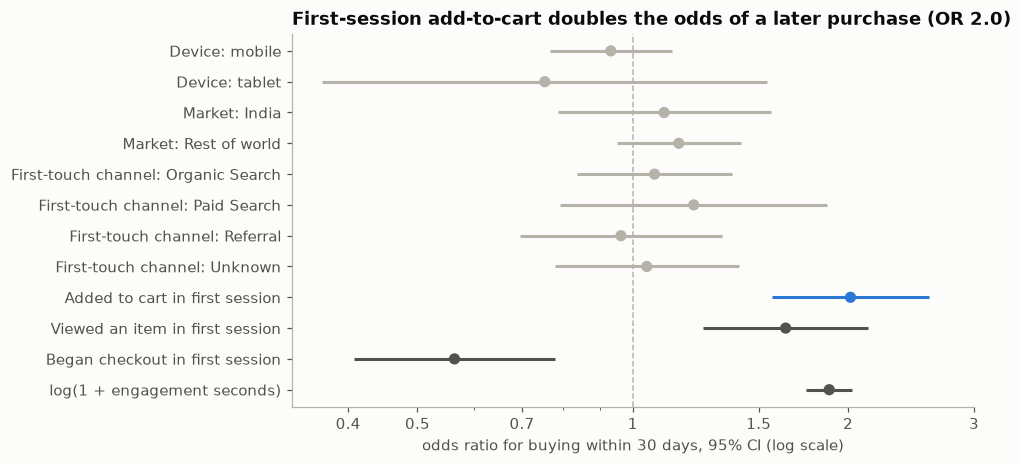

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.4))
o = odds.iloc[::-1].reset_index(drop=True)
colors = [a.BLUE if t.startswith("Added to cart") else (a.MUTED if (lo > 1 or hi < 1) else a.GRAY)
          for t, lo, hi in zip(o.term, o.ci_low, o.ci_high)]
ax.hlines(o.index, o.ci_low, o.ci_high, colors=colors, lw=2)
ax.scatter(o.odds_ratio, o.index, color=colors, s=40, zorder=3)
ax.axvline(1, color=a.GRAY, lw=1, ls="--")
ax.set_xscale("log")
ax.set_yticks(o.index, o.term)
ax.set_xticks([0.4, 0.5, 0.7, 1, 1.5, 2, 3])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("odds ratio for buying within 30 days, 95% CI (log scale)")
act = odds.set_index("term").loc["Added to cart in first session"]
ax.set_title(f"First-session add-to-cart doubles the odds of a later purchase (OR {act.odds_ratio:.1f})")
fig.savefig("charts/activation_odds.png")

Holding engagement and the other first-session signals fixed, adding to cart roughly doubles the odds of buying within 30 days. Engagement time is the strongest single predictor.

Beginning checkout without buying *lowers* the odds once the other signals are fixed. A plausible reading is that some of these users saw the price or shipping cost and left; the data cannot confirm it.

Device, market and first-touch channel add nothing once behaviour is known. The model ranks well out of time, and its top decile holds about three in five later buyers.

## Weekly retention

Share of each weekly new-user cohort with a session in week *k*. The first cohort week contains only 1 November.

In [5]:
ret = q("SELECT * FROM retention_cohorts WHERE week_number <= 8")
matrix = ret.pivot(index="cohort_week", columns="week_number", values="retention")
sizes = ret.drop_duplicates("cohort_week").set_index("cohort_week").cohort_users
matrix = matrix[matrix.drop(columns=0).notna().any(axis=1)]
matrix.index = [f"w/c {w:%d %b} (n={sizes[w]:,})" for w in matrix.index]
matrix.style.format("{:.1%}", na_rep="").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.08)

week_number,0,1,2,3,4,5,6,7,8
"w/c 26 Oct (n=1,969)",100.0%,6.1%,1.6%,0.9%,0.5%,0.4%,0.2%,0.1%,0.2%
"w/c 02 Nov (n=16,703)",100.0%,4.2%,1.9%,1.4%,1.2%,1.0%,0.7%,0.2%,0.2%
"w/c 09 Nov (n=14,778)",100.0%,5.7%,2.4%,1.7%,1.8%,0.9%,0.5%,0.2%,0.4%
"w/c 16 Nov (n=17,084)",100.0%,5.2%,2.8%,2.0%,1.5%,0.5%,0.3%,0.3%,0.3%
"w/c 23 Nov (n=19,280)",100.0%,4.7%,2.2%,1.3%,0.6%,0.4%,0.4%,0.4%,0.3%
"w/c 30 Nov (n=21,413)",100.0%,5.0%,2.1%,0.8%,0.6%,0.6%,0.4%,0.3%,0.3%
"w/c 07 Dec (n=27,939)",100.0%,3.1%,0.9%,0.6%,1.0%,0.5%,0.3%,0.3%,
"w/c 14 Dec (n=24,451)",100.0%,2.8%,0.9%,1.2%,0.9%,0.5%,0.4%,,
"w/c 21 Dec (n=17,199)",100.0%,2.5%,1.1%,1.0%,0.6%,0.4%,,,
"w/c 28 Dec (n=16,455)",100.0%,2.4%,0.9%,0.6%,0.4%,,,,


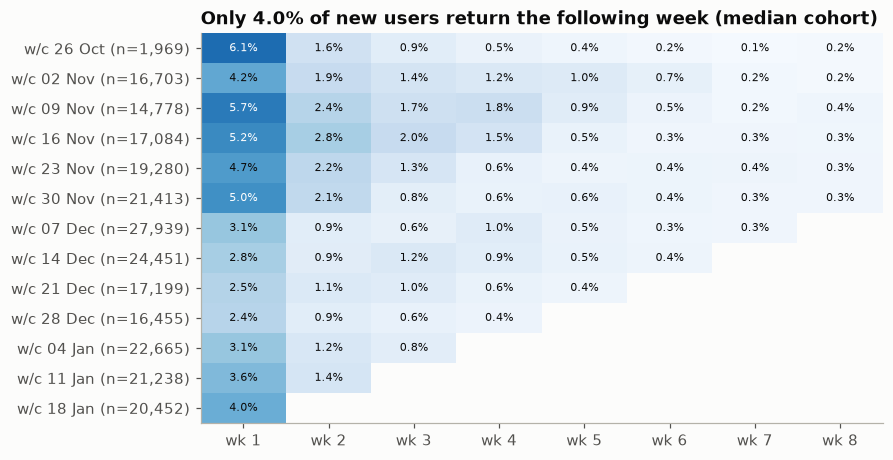

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6))
m = matrix.drop(columns=0)
im = ax.imshow(m.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=0.08, aspect="auto")
ax.set_xticks(range(m.shape[1]), [f"wk {c}" for c in m.columns])
ax.set_yticks(range(m.shape[0]), m.index)
for (i, j), v in np.ndenumerate(m.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7, color="white" if v > 0.05 else a.INK)
week1 = ret[ret.week_number == 1].retention.median()
ax.set_title(f"Only {week1:.1%} of new users return the following week (median cohort)")
fig.savefig("charts/retention.png")

## North star: weekly purchasing users

Guardrails: AOV and revenue per session. Full weeks inside the order window only.

In [7]:
ns = q("SELECT * FROM weekly_north_star")
print("correlation of weekly purchasing users with weekly revenue:", round(ns.purchasing_users.corr(ns.revenue_usd), 3))
ns

correlation of weekly purchasing users with weekly revenue: 0.992


,week,days,purchasing_users,sessions,orders,revenue_usd,aov,revenue_per_session
0,2020-11-16,7,343,25914,379.0000,"26,549.0000",70.0501,1.0245
1,2020-11-23,7,473,27780,534.0000,"40,146.0000",75.1798,1.4451
2,2020-11-30,7,546,31088,610.0000,"42,725.0000",70.0410,1.3743
3,2020-12-07,7,709,38729,823.0000,"59,100.0000",71.8104,1.5260
4,2020-12-14,7,506,33411,658.0000,"46,240.0000",70.2736,1.3840
5,2020-12-21,7,223,22083,245.0000,"14,470.0000",59.0612,0.6553
6,2020-12-28,7,129,20444,140.0000,"10,123.0000",72.3071,0.4952
7,2021-01-04,7,152,29029,159.0000,"9,225.0000",58.0189,0.3178
8,2021-01-11,7,204,27707,228.0000,"12,827.0000",56.2588,0.4630
9,2021-01-18,7,339,27478,365.0000,"26,668.0000",73.0630,0.9705


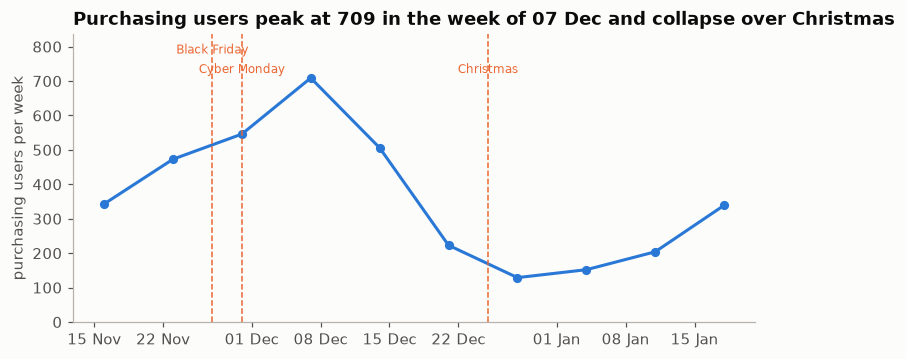

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ns.week, ns.purchasing_users, color=a.BLUE, lw=2, marker="o", ms=5)
for (name, day), lift in zip(a.HOLIDAYS.items(), [1.10, 1.02, 1.02]):
    ax.axvline(pd.Timestamp(day), color=a.ORANGE, lw=1, ls="--")
    ax.text(pd.Timestamp(day), ns.purchasing_users.max() * lift, name, color=a.ORANGE, fontsize=8, ha="center")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax.set_ylabel("purchasing users per week")
ax.set_ylim(0, ns.purchasing_users.max() * 1.18)
peak = ns.loc[ns.purchasing_users.idxmax()]
ax.set_title(f"Purchasing users peak at {peak.purchasing_users:,} in the week of {peak.week:%d %b} and collapse over Christmas")
fig.savefig("charts/north_star.png")
con.close()

Weekly purchasing users track revenue almost one for one, so it works as a north star.

AOV stays at $56–75 even through the Christmas collapse. Revenue per session moves with purchasing users. That is why AOV is a guardrail rather than a target: a test that raised buyers by pushing AOV down would show up there.